# FSI2 数据整理

In [8]:
from pathlib import Path
import pandas as pd

data_dir = Path("../data/smoke_005")
methods = ["similarity", "laplacian", "laplacian_prcg", "laplacian_nn"]


def read_results(data_dir, methods):
    tables = []
    for method in methods:
        for filename in ("mesh_smoothing.csv", "evaluation.csv"):
            table = pd.read_csv(data_dir / method / filename)
            if filename == "evaluation.csv":
                table.insert(0, "record_type", "evaluation")
            table.insert(0, "method", method)
            tables.append(table)

    return pd.concat(tables, ignore_index=True)


data = read_results(data_dir, methods)
display(data)

,method,record_type,step,time,min_J,min_q,mean_q,prcg_calls,prcg_seconds,smoothing_seconds,rejected_calls,reason,total_seconds,completed,tip_dx,tip_dy,drag,lift,optimizer_calls,optimizer_seconds
0,similarity,configuration,0.0,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"{""settings"": {""enable_smoothing"": false, ""qual...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,similarity,step,1.0,0.002,0.000001,0.636732,0.98186,0.0,0.0,0.174766,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,similarity,step,2.0,0.004,0.000001,0.636732,0.98186,0.0,0.0,0.159338,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,similarity,step,3.0,0.006,0.000001,0.636732,0.98186,0.0,0.0,0.155813,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,similarity,step,4.0,0.008,0.000001,0.636732,0.98186,0.0,0.0,0.451257,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123,laplacian_nn,evaluation,NaN,0.010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-1.251378e-06,-1.346992e-07,-0.029761,-15.228394,NaN,NaN
124,laplacian_nn,evaluation,NaN,0.020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.682928e-07,-3.935574e-08,-0.664133,109.613460,NaN,NaN
125,laplacian_nn,evaluation,NaN,0.030,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-2.971889e-06,5.991138e-08,2.626844,-3.230378,NaN,NaN
126,laplacian_nn,evaluation,NaN,0.040,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-3.192883e-06,1.531583e-08,0.411645,2.004187,NaN,NaN


## 网格质量

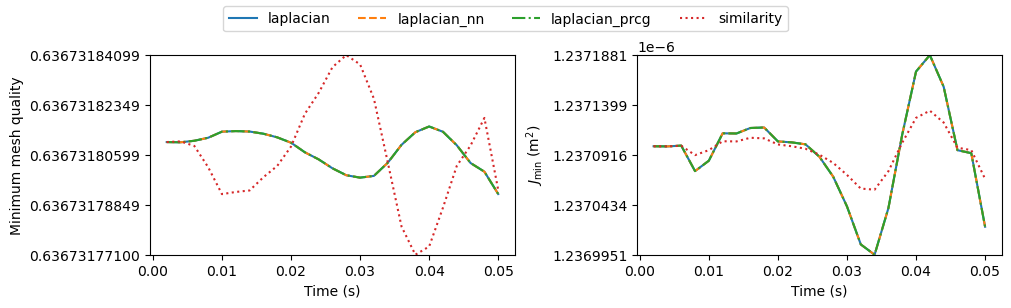

In [9]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter, LinearLocator


def set_y_axis(axis, values, tick_format="%.2f", bottom=None):
    low = values.min() if bottom is None else bottom
    axis.set_ylim(low, values.max())
    axis.yaxis.set_major_locator(LinearLocator(5))
    axis.ticklabel_format(axis="y", useOffset=False)

    formatter = FormatStrFormatter(tick_format)
    labels = list(map(formatter, axis.get_yticks()))
    # Keep Matplotlib's automatic precision when rounding merges ticks.
    if len(set(labels)) == len(labels):
        axis.yaxis.set_major_formatter(formatter)


mesh_metrics = ["min_q", "min_J"]
mesh_curves = data.dropna(subset=mesh_metrics, how="all").pivot(
    index="time", columns="method", values=mesh_metrics
)
line_styles = ["-", "--", "-.", ":"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
mesh_curves["min_q"].plot(
    ax=axes[0], xlabel="Time (s)", ylabel="Minimum mesh quality",
    style=line_styles, legend=False,
)
set_y_axis(axes[0], data["min_q"])
mesh_curves["min_J"].plot(
    ax=axes[1], xlabel="Time (s)", ylabel=r"$J_{\min}$ (m$^2$)",
    style=line_styles, legend=False,
)
set_y_axis(axes[1], data["min_J"], "%.2e")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper center", ncol=4)
plt.show()

## 梁尖位移与流体力

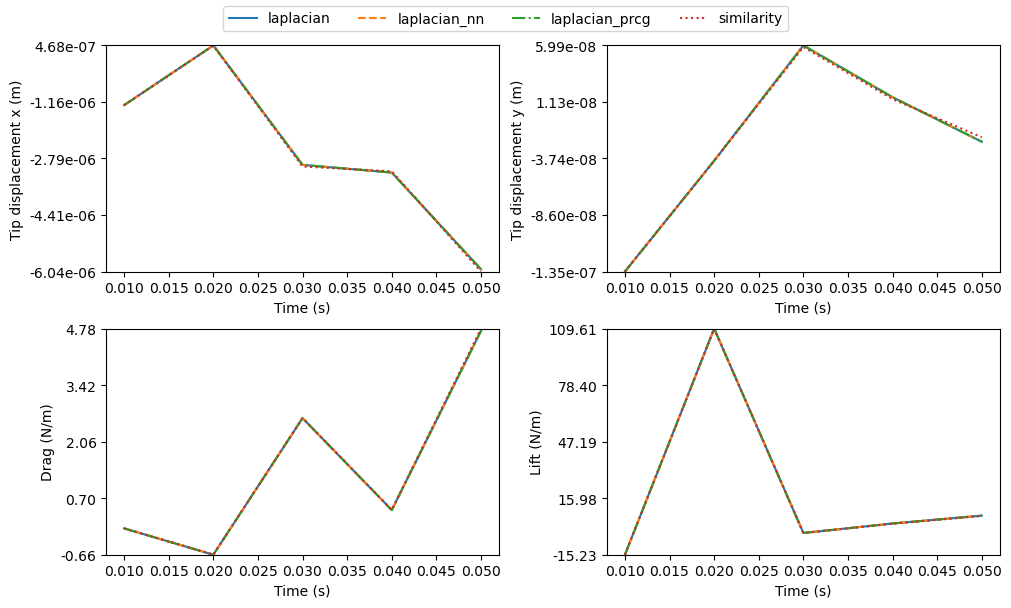

In [10]:
response_metrics = ["tip_dx", "tip_dy", "drag", "lift"]
response_curves = data.dropna(subset=response_metrics, how="all").pivot(
    index="time", columns="method", values=response_metrics
)
fig, axes = plt.subplots(2, 2, figsize=(10, 6), layout="constrained")
response_curves["tip_dx"].plot(
    ax=axes[0, 0], xlabel="Time (s)", ylabel="Tip displacement x (m)",
    style=line_styles, legend=False,
)
response_curves["tip_dy"].plot(
    ax=axes[0, 1], xlabel="Time (s)", ylabel="Tip displacement y (m)",
    style=line_styles, legend=False,
)
response_curves["drag"].plot(
    ax=axes[1, 0], xlabel="Time (s)", ylabel="Drag (N/m)", style=line_styles, legend=False
)
response_curves["lift"].plot(
    ax=axes[1, 1], xlabel="Time (s)", ylabel="Lift (N/m)", style=line_styles, legend=False
)
set_y_axis(axes[0, 0], data["tip_dx"], "%.2e")
set_y_axis(axes[0, 1], data["tip_dy"], "%.2e")
set_y_axis(axes[1, 0], data["drag"])
set_y_axis(axes[1, 1], data["lift"])
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=4)
plt.show()

## time cost

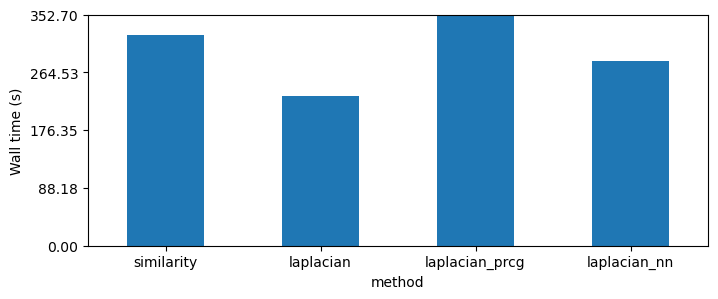

In [11]:
axis = data.dropna(subset=["total_seconds"]).plot.bar(
    x="method", y="total_seconds", ylabel="Wall time (s)",
    figsize=(8, 3), rot=0, legend=False,
)
set_y_axis(axis, data["total_seconds"], bottom=0)
plt.show()